In [1]:
import pandas as pd
import numpy as np

Series

In [2]:
data = [10, 20, 30, 40]
labels = ['a', 'b', 'c', 'd']

series = pd.Series(data)
print(series)

series = pd.Series(data,index=labels)
print(series)

0    10
1    20
2    30
3    40
dtype: int64
a    10
b    20
c    30
d    40
dtype: int64


In [3]:
d_data = {'Apple': 1.2, 'Banana': 0.5, 'Cherry': 2.5}
fruit_series = pd.Series(d_data.values(),index=d_data.keys())
print("\n--- Series from Dictionary ---")
print(fruit_series)


--- Series from Dictionary ---
Apple     1.2
Banana    0.5
Cherry    2.5
dtype: float64


In [4]:
print(series * 2)

a    20
b    40
c    60
d    80
dtype: int64


Dataframe

In [5]:
names =['Alice','Bob','Charlie','David']
age=[25,30,35,40]
city=['Newyork','London','Paris','Tokyo']
data={'Name':names,'Age':age,'City':city}
df=pd.DataFrame(data)
print(df)

      Name  Age     City
0    Alice   25  Newyork
1      Bob   30   London
2  Charlie   35    Paris
3    David   40    Tokyo


In [9]:
df=pd.read_csv('../data/products_100.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   product_name  100 non-null    str  
 1   type          100 non-null    str  
 2   price         100 non-null    int64
 3   quant         100 non-null    int64
dtypes: int64(2), str(2)
memory usage: 3.3 KB


In [10]:
df.shape

(100, 4)

In [11]:
df.sample(10)

,product_name,type,price,quant
33,Cooking Oil,Grocery,1544,3
37,Sweater,Clothing,342,10
21,Bedsheet,Home,1133,1
29,Folder,Stationery,983,5
56,Cushion,Home,2440,7
28,Pasta,Grocery,334,1
81,Mug,Home,1581,3
1,Lamp,Home,1176,4
34,Sticky Notes,Stationery,1566,6
26,Curtains,Home,1531,10


Aggregators

In [12]:
print(df['price'].mean())

1201.05


In [ ]:
print(df['price'].median())

1024.0


In [ ]:
print(df['price'].std())

1722.3201545143872


In [ ]:
print(df['quant'].median())

9.5


In [ ]:
print(df['quant'].mode())

0    2
Name: quant, dtype: int64


In [ ]:
df.describe()

,price,quant
count,100.000000,100.000000
mean,1576.550000,23.220000
std,1722.320155,31.891096
min,25.000000,1.000000
25%,276.750000,3.000000
50%,1024.000000,9.500000
75%,2049.000000,30.000000
max,8999.000000,150.000000


In [ ]:
df[df['quant']==2]

,product_name,type,price,quant
20,Product_21,Electronics,2499,2
23,Product_24,Electronics,3499,2
36,Product_37,Clothing,2499,2
41,Product_42,Clothing,6499,2
44,Product_45,Clothing,4599,2
56,Product_57,Grocery,2799,2
60,Product_61,Grocery,3999,2
61,Product_62,Grocery,4299,2
82,Product_83,Home,2899,2
83,Product_84,Home,3199,2


Counts

In [ ]:
df['type'].unique()

array(['Electronics', 'Clothing', 'Grocery', 'Home'], dtype=object)

In [ ]:
df['product_name'].nunique()

100

In [ ]:
df['type'].value_counts()

,count
type,
Electronics,25
Clothing,25
Grocery,25
Home,25


In [ ]:
df['product_name'].value_counts()

,count
product_name,
Product_1,1
Product_2,1
Product_3,1
Product_4,1
Product_5,1
...,...
Product_96,1
Product_97,1
Product_98,1


Filtering based on condition

In [ ]:
df[df['type']=='Electronics']

,product_name,type,price,quant
0,Product_1,Electronics,1299,5
1,Product_2,Electronics,999,8
2,Product_3,Electronics,1599,3
3,Product_4,Electronics,799,12
4,Product_5,Electronics,1899,4
5,Product_6,Electronics,499,20
6,Product_7,Electronics,699,15
7,Product_8,Electronics,999,10
8,Product_9,Electronics,1299,7
9,Product_10,Electronics,399,25


In [ ]:
df[df['price']<=500]

,product_name,type,price,quant
5,Product_6,Electronics,499,20
9,Product_10,Electronics,399,25
10,Product_11,Electronics,120,50
11,Product_12,Electronics,80,60
12,Product_13,Electronics,150,40
13,Product_14,Electronics,200,35
14,Product_15,Electronics,60,70
19,Product_20,Electronics,499,18
30,Product_31,Clothing,90,55
31,Product_32,Clothing,110,45


In [ ]:
df[(df['type']=='Home') | (df['type']=='Electronics')]

,product_name,type,price,quant
0,Product_1,Electronics,1299,5
1,Product_2,Electronics,999,8
2,Product_3,Electronics,1599,3
3,Product_4,Electronics,799,12
4,Product_5,Electronics,1899,4
5,Product_6,Electronics,499,20
6,Product_7,Electronics,699,15
7,Product_8,Electronics,999,10
8,Product_9,Electronics,1299,7
9,Product_10,Electronics,399,25


In [ ]:
lowcost_elec = df[(df['price']<500) & (df['type'] == 'Electronics')]

In [ ]:
print(lowcost_elec)

   product_name         type  price  quant
5     Product_6  Electronics    499     20
9    Product_10  Electronics    399     25
10   Product_11  Electronics    120     50
11   Product_12  Electronics     80     60
12   Product_13  Electronics    150     40
13   Product_14  Electronics    200     35
14   Product_15  Electronics     60     70
19   Product_20  Electronics    499     18


Categorical Values and Corelation

In [ ]:
df[['price', 'quant']].corr()

,price,quant
price,1.000000,-0.528948
quant,-0.528948,1.000000


In [ ]:
categorical_cols = df.select_dtypes(include=['object'])
print(categorical_cols.head())
print(categorical_cols.tail())

  product_name         type
0    Product_1  Electronics
1    Product_2  Electronics
2    Product_3  Electronics
3    Product_4  Electronics
4    Product_5  Electronics
   product_name  type
95   Product_96  Home
96   Product_97  Home
97   Product_98  Home
98   Product_99  Home
99  Product_100  Home


In [ ]:
numerical_cols = df.select_dtypes(include=['int64', 'float64'])
print(numerical_cols.head())

   price  quant
0   1299      5
1    999      8
2   1599      3
3    799     12
4   1899      4


In [ ]:
df[['price', 'quant']].corr()

,price,quant
price,1.000000,-0.528948
quant,-0.528948,1.000000


Groupby

In [15]:
df.groupby('type')['price'].max()

type
Clothing       2331
Electronics    2468
Grocery        2463
Home           2440
Stationery     2283
Name: price, dtype: int64

In [16]:
df.groupby('type').agg({
    'price': ['mean', 'max', 'min'],
    'quant': ['mean', 'sum']
})

price            quant     
                mean   max  min  mean  sum
type                                      
Clothing     1152.90  2331  342  8.05  161
Electronics  1390.35  2468  129  6.25  125
Grocery      1053.70  2463   52  7.55  151
Home         1348.45  2440  180  5.70  114
Stationery   1059.85  2283   63  6.15  123

In [ ]:
df.groupby('type')['product_name'].count()

,product_name
type,
Clothing,25
Electronics,25
Grocery,25
Home,25


nan NaN

In [ ]:
df.groupby(['type'])[['price', 'quant']].mean()


,price,quant
type,,
Clothing,1943.2,19.28
Electronics,1155.6,17.12
Grocery,1767.6,28.20
Home,1439.8,28.28


In [17]:
df['revenue'] = df['price'] * df['quant']

In [18]:
df.head()

,product_name,type,price,quant,revenue
0,Headphones,Electronics,506,1,506
1,Lamp,Home,1176,4,4704
2,T-Shirt,Clothing,964,3,2892
3,Rice,Grocery,469,11,5159
4,Notebook,Stationery,2283,2,4566


In [19]:
print(type(float('nan')))

<class 'float'>


In [ ]:
df.head()

,product_name,type,price,quant,revenue
0,Product_1,Electronics,1299,5,6495
1,Product_2,Electronics,999,8,7992
2,Product_3,Electronics,1599,3,4797
3,Product_4,Electronics,799,12,9588
4,Product_5,Electronics,1899,4,7596


In [20]:
df.shape

(100, 5)

In [23]:
df.groupby('type')['revenue'].mean()

type
Clothing       9091.60
Electronics    9306.95
Grocery        7711.55
Home           7730.15
Stationery     5907.00
Name: revenue, dtype: float64

Sorting in Dataframes

In [24]:
df_sorted = df.sort_values('price',ascending=False)
df_sorted.head()

,product_name,type,price,quant,revenue
5,Mouse,Electronics,2468,7,17276
13,Sugar,Grocery,2463,5,12315
55,Mouse,Electronics,2444,7,17108
56,Cushion,Home,2440,7,17080
53,Rice,Grocery,2349,9,21141


In [25]:
df_sorted.head()

,product_name,type,price,quant,revenue
5,Mouse,Electronics,2468,7,17276
13,Sugar,Grocery,2463,5,12315
55,Mouse,Electronics,2444,7,17108
56,Cushion,Home,2440,7,17080
53,Rice,Grocery,2349,9,21141


In [26]:
df.sort_values(['type', 'price'], ascending=[True, False])

,product_name,type,price,quant,revenue
42,Shorts,Clothing,2331,4,9324
82,Shirt,Clothing,2259,9,20331
97,Scarf,Clothing,2258,12,27096
22,Hoodie,Clothing,1931,9,17379
57,Jeans,Clothing,1532,4,6128
...,...,...,...,...,...
89,Eraser,Stationery,372,2,744
64,Pencil Box,Stationery,310,7,2170
9,Pen Set,Stationery,158,9,1422
14,Pencil Box,Stationery,76,3,228


In [27]:
df_sorted = df.sort_values('price')
df_sorted.head()

,product_name,type,price,quant,revenue
83,Cooking Oil,Grocery,52,10,520
74,Marker,Stationery,63,12,756
14,Pencil Box,Stationery,76,3,228
68,Tea,Grocery,97,11,1067
85,Charger,Electronics,129,2,258


In [28]:
df_sorted = df.sort_values('price').reset_index(drop=False)
df_sorted.head()

,index,product_name,type,price,quant,revenue
0,83,Cooking Oil,Grocery,52,10,520
1,74,Marker,Stationery,63,12,756
2,14,Pencil Box,Stationery,76,3,228
3,68,Tea,Grocery,97,11,1067
4,85,Charger,Electronics,129,2,258


In [29]:
df_copy = df.copy()

In [30]:
df_copy.sort_values('price')

,product_name,type,price,quant,revenue
83,Cooking Oil,Grocery,52,10,520
74,Marker,Stationery,63,12,756
14,Pencil Box,Stationery,76,3,228
68,Tea,Grocery,97,11,1067
85,Charger,Electronics,129,2,258
...,...,...,...,...,...
53,Rice,Grocery,2349,9,21141
56,Cushion,Home,2440,7,17080
55,Mouse,Electronics,2444,7,17108
13,Sugar,Grocery,2463,5,12315


Plotting in Pandas

<Axes: >

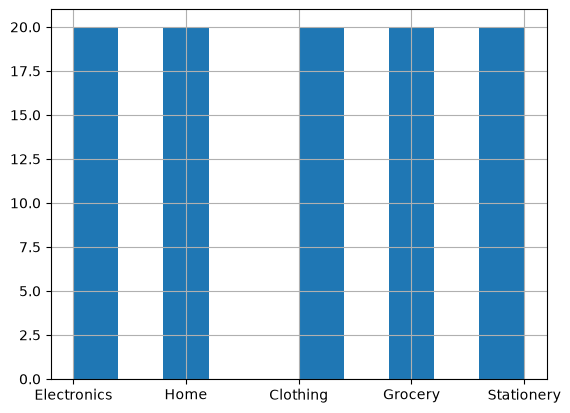

In [31]:
df['type'].hist()

<Axes: >

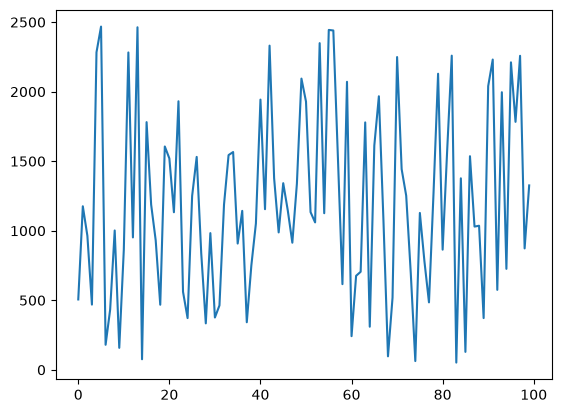

In [32]:
df['price'].plot()

<Axes: title={'center': 'Price Trend'}>

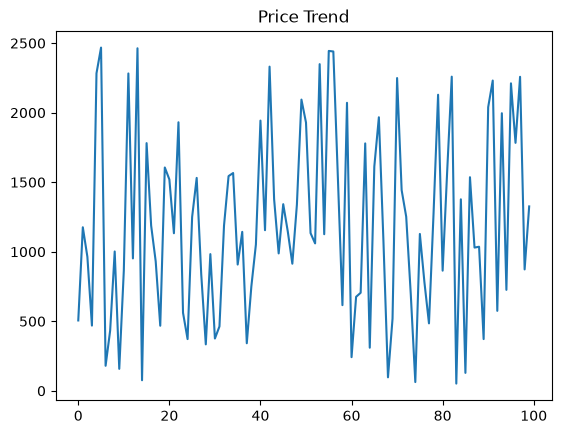

In [33]:
df['price'].plot(title="Price Trend")

<Axes: title={'center': 'Mean Price'}, xlabel='type'>

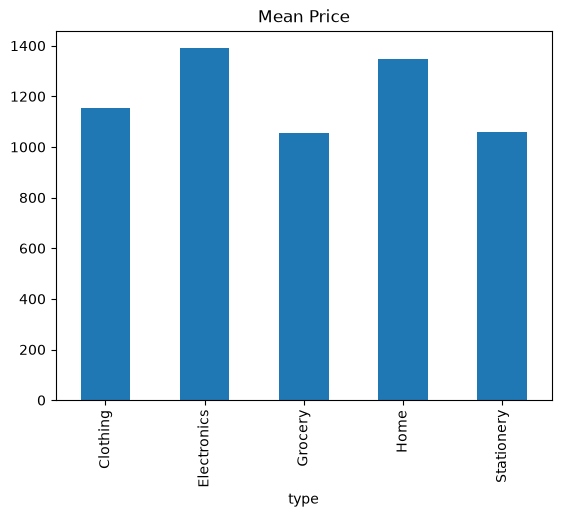

In [35]:
df.groupby('type')['price'].mean().plot(kind='bar',title='Mean Price')

<Axes: ylabel='Frequency'>

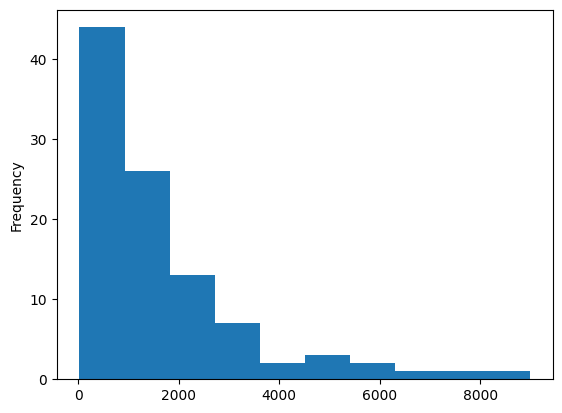

In [ ]:
df['price'].plot(kind='hist', bins=10)

<Axes: xlabel='price', ylabel='quant'>

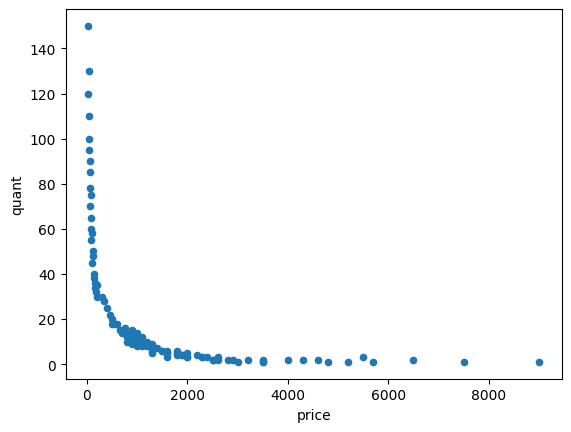

In [ ]:
df.plot(kind='scatter', x='price', y='quant')

1. .loc selects by label , the actual index values and column names.
2. .
iloc selects by integer position 0, 1, 2 , ignoring labels.

In [36]:

import pandas as pd

# 1. Create dataset with Employee details
data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'David', 'Eva'],
    'Age': [25, 30, 35, 40, 28],
    'Department': ['HR', 'IT', 'Finance', 'IT', 'Marketing'],
    'Salary': [50000, 75000, 85000, 90000, 62000]
}

df1 = pd.DataFrame(data, index=None)

print("--- DataFrame ---")
print(df1)



--- DataFrame ---
      Name  Age Department  Salary
0    Alice   25         HR   50000
1      Bob   30         IT   75000
2  Charlie   35    Finance   85000
3    David   40         IT   90000
4      Eva   28  Marketing   62000


In [37]:
# 2. Assign custom alphabetic labels as index
indices = ['a', 'b', 'c', 'd', 'e']
df2 = pd.DataFrame(data, index=indices)

print("--- DataFrame ---")
print(df2)

--- DataFrame ---
      Name  Age Department  Salary
a    Alice   25         HR   50000
b      Bob   30         IT   75000
c  Charlie   35    Finance   85000
d    David   40         IT   90000
e      Eva   28  Marketing   62000


In [38]:
# --- 1. Fetching a single row ---
# Using label 'b'
print(df2.loc['b'])

# Using row position 1 (which corresponds to 'b')
print(df1.iloc[1])


# --- 2. Slicing rows ---
# .loc includes 'c' (returns rows 'a', 'b', 'c')
#print(df2.loc['a':'c'])

# .iloc excludes index position 3 (returns positions 0, 1, 2)
#print(df1.iloc[0:3])


# --- 3. Selecting specific rows and
#  columns ---
# .loc uses explicit row labels and column names
#print(df2.loc[['a', 'd'], ['Name', 'Salary']])

# .iloc uses numerical row positions [0, 3] and column positions [0, 3]
#print(df1.iloc[[0, 3], [0, 3]])

Name            Bob
Age              30
Department       IT
Salary        75000
Name: b, dtype: object
Name            Bob
Age              30
Department       IT
Salary        75000
Name: 1, dtype: object
